# Лабораторная 2. Временные ряды. Стационарность
**Выполнила:** Окулова Александра ИТ-14

In [1]:
# Imports
import warnings
warnings.filterwarnings('ignore')
from io import BytesIO
import requests
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import quad
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
np.random.seed(0) # Reproducibility

def run_sequence_plot(x, y, title, xlabel="Time", ylabel="Values", ax=None):
    if ax is None:
        _, ax = plt.subplots(1,1, figsize=(10, 3.5))
    ax.plot(x, y, 'g-')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    return ax

### Упражнение 1

    Загрузите два временных ряда stationarity_ts1 и stationarity_ts2, выполнив код ниже.

1. Постройте два временных ряда с помощью графика последовательности запусков.
2. На основе графика обсудите, является ли каждый временной ряд стационарным или нет.

100
100


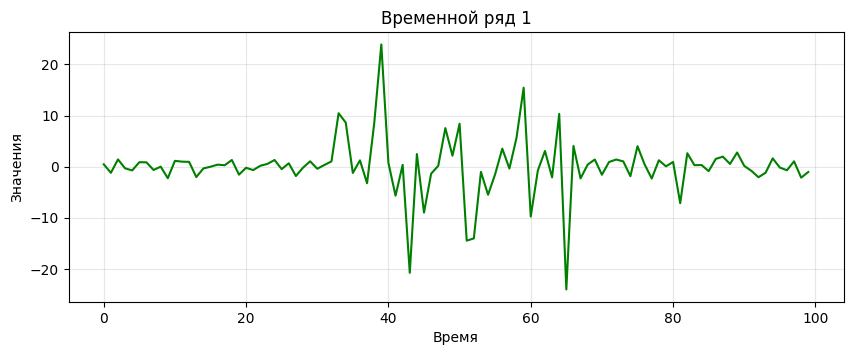

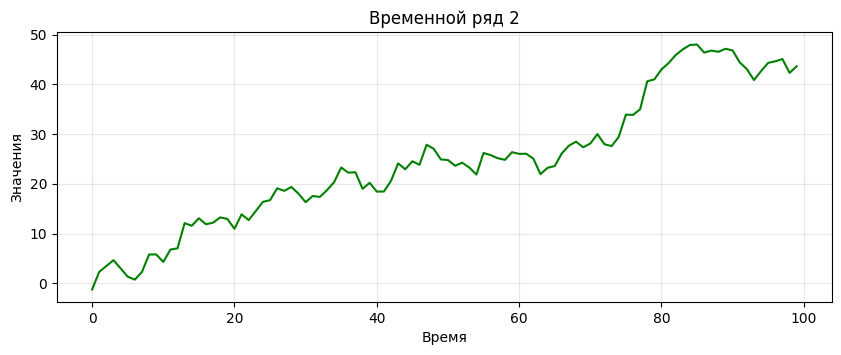

In [2]:

# Load the first time series
response = requests.get("https://zenodo.org/records/10897398/files/stationarity_ts1.npy?download=1")
response.raise_for_status()
stationarity_ts1 = np.load(BytesIO(response.content))
print(len(stationarity_ts1))

# Load the second time series
response = requests.get("https://zenodo.org/records/10897398/files/stationarity_ts2.npy?download=1")
response.raise_for_status()
stationarity_ts2 = np.load(BytesIO(response.content))
print(len(stationarity_ts2))

time1 = np.arange(len(stationarity_ts1))
time2 = np.arange(len(stationarity_ts2))

run_sequence_plot(time1, stationarity_ts1,
                  title="Временной ряд 1",
                  xlabel="Время", ylabel="Значения")

run_sequence_plot(time2, stationarity_ts2,
                  title="Временной ряд 2",
                  xlabel="Время", ylabel="Значения")

plt.show()


### Вывод

На основе визуального анализа графиков можно сделать следующие выводы:

1. **Временной ряд 1** является нестационарным. Математическое ожидание приблизительно постоянно, однако дисперсия изменяется со временем. В середине ряда наблюдается значительное увеличение амплитуды колебаний по сравнению с началом и концом ряда.

2. **Временной ряд 2** является нестационарным. На графике наблюдается выраженный восходящий тренд, вследствие чего среднее значение ряда изменяется со временем.

Таким образом, оба временных ряда имеют признаки нестационарности: первый - по дисперсии, второй - по математическому ожиданию.

### Упражнение 2

Используйте следующие инструменты, чтобы определить, являются ли временные ряды stationarity_ts1 и stationarity_ts2 стационарными или нет.

    Сводная статистика по фрагментам.
    Гистограммы.
    Расширенный тест Дики-Фуллера.

Обсудите результат, полученный с помощью каждого метода.

In [3]:
#Сводная статисика по фрагментам
#Разбиваем ряды на 10 фрагментов
chunks1 = np.split(stationarity_ts1, 10)
chunks2 = np.split(stationarity_ts2, 10)

print("Сводная статистика по фрагментам")
print("Временной ряд 1")
print("{}\t | {}\t\t | {}".format("Chunk", "Mean", "Variance"))
print("-" * 35)
for i, chunk1 in enumerate(chunks1, 1):
    print("{:2}\t | {:.5}\t | {:.5}".format(i, np.mean(chunk1), np.var(chunk1)))

print("\nВременной ряд 2")
print("{}\t | {}\t\t | {}".format("Chunk", "Mean", "Variance"))
print("-" * 35)
for i, chunk2 in enumerate(chunks2, 1):
    print("{:2}\t | {:.5}\t | {:.5}".format(i, np.mean(chunk2), np.var(chunk2)))


Сводная статистика по фрагментам
Временной ряд 1
Chunk	 | Mean		 | Variance
-----------------------------------
 1	 | -0.14368	 | 1.1065
 2	 | 0.12109	 | 1.1652
 3	 | 0.047148	 | 0.76635
 4	 | 4.9208	 | 59.92
 5	 | -2.3263	 | 55.947
 6	 | -0.37065	 | 79.168
 7	 | -1.9508	 | 77.816
 8	 | 0.34635	 | 3.1884
 9	 | 0.30483	 | 7.293
10	 | -0.51908	 | 1.3469

Временной ряд 2
Chunk	 | Mean		 | Variance
-----------------------------------
 1	 | 2.8186	 | 4.5026
 2	 | 10.511	 | 9.3034
 3	 | 16.023	 | 7.5191
 4	 | 19.733	 | 4.9789
 5	 | 23.268	 | 9.4271
 6	 | 24.608	 | 1.7717
 7	 | 25.543	 | 3.9608
 8	 | 32.736	 | 22.713
 9	 | 46.289	 | 2.2247
10	 | 43.773	 | 2.4782


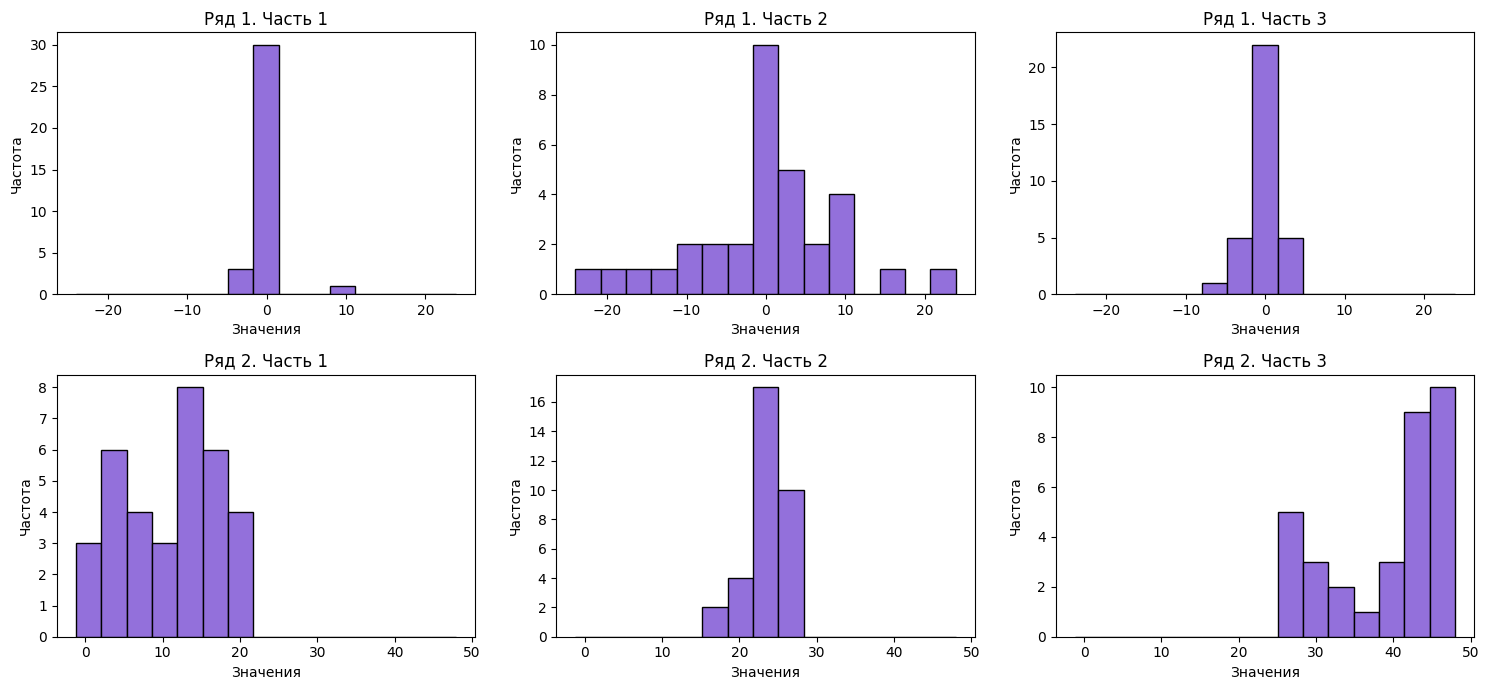

In [4]:
#Гистограммы
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

parts1 = np.array_split(stationarity_ts1, 3)
parts2 = np.array_split(stationarity_ts2, 3)
bins1 = np.histogram_bin_edges(stationarity_ts1, bins=15)
bins2 = np.histogram_bin_edges(stationarity_ts2, bins=15)

for i in range(3):
    axes[0, i].hist(parts1[i], bins=bins1, color="mediumpurple", edgecolor="black")
    axes[0, i].set_title(f"Ряд 1. Часть {i + 1}")
    axes[0, i].set_xlabel("Значения")
    axes[0, i].set_ylabel("Частота")
    axes[1, i].hist(parts2[i], bins=bins2, color="mediumpurple", edgecolor="black")
    axes[1, i].set_title(f"Ряд 2. Часть {i + 1}")
    axes[1, i].set_xlabel("Значения")
    axes[1, i].set_ylabel("Частота")

plt.tight_layout()
plt.show()


**Расширенный тест Дики-Фуллера**

    Это статистическая процедура для определения того, является ли временной ряд стационарным или нет.
    Мы обсудим тест более подробно на следующих лекциях.
    На данный момент нам нужно знать следующее:

    Нулевая гипотеза:
    Н0: ряд нестационарный.
    Альтернативная гипотеза:
    На: ряд стационарный.
Уровень значимости = 0.05

In [5]:

# Тест ADF для первого ряда
adf1, pvalue1, _, _, critical_values1, _ = adfuller(stationarity_ts1)

print("Расширенный тест Дики-Фуллера")
print("Временной ряд 1")
print(f"ADF: {adf1:.3f}")
print(f"p-value: {pvalue1:.6f}")
print("Критические значения:", critical_values1)

# Тест ADF для второго ряда
adf2, pvalue2, _, _, critical_values2, _ = adfuller(stationarity_ts2)

print("\nВременной ряд 2")
print(f"ADF: {adf2:.3f}")
print(f"p-value: {pvalue2:.6f}")
print("Критические значения:", critical_values2)


Расширенный тест Дики-Фуллера
Временной ряд 1
ADF: -3.032
p-value: 0.031976
Критические значения: {'1%': np.float64(-3.50434289821397), '5%': np.float64(-2.8938659630479413), '10%': np.float64(-2.5840147047458037)}

Временной ряд 2
ADF: -1.322
p-value: 0.618926
Критические значения: {'1%': np.float64(-3.498198082189098), '5%': np.float64(-2.891208211860468), '10%': np.float64(-2.5825959973472097)}


### Вывод

**1. Сводная статистика по фрагментам**

У первого временного ряда средние значения колеблются около нуля, однако дисперсия существенно изменяется: от 0.766 до 79.168. Это свидетельствует о нестационарности ряда по дисперсии.

У второго временного ряда среднее значение увеличивается с 2.819 до 46.289, что свидетельствует о наличии восходящего тренда и нестационарности ряда по математическому ожиданию.

**2. Гистограммы**

У первого ряда в начале и конце значения сосредоточены около нуля, а в середине наблюдается значительное увеличение разброса.

У второго ряда распределение значений постепенно смещается вправо, что указывает на изменение среднего значения со временем.

Таким образом, гистограммы подтверждают нестационарность обоих рядов.

**3. Расширенный тест Дики - Фуллера**

Для первого ряда p-value = 0.031976 < 0.05, поэтому нулевая гипотеза отвергается. Тест свидетельствует в пользу стационарности ряда. Однако он не выявляет изменение дисперсии, наблюдаемое при анализе другими методами.

Для второго ряда p-value = 0.618926 > 0.05, поэтому нулевая гипотеза не отвергается. Оснований считать ряд стационарным по результатам теста нет.

**Общий вывод:** оба временных ряда являются нестационарными. Первый ряд имеет изменяющуюся дисперсию, второй - изменяющееся математическое ожидание. Для определения стационарности необходимо использовать несколько методов анализа, поскольку тест Дики - Фуллера не выявляет все виды нестационарности.

### Упражнение 3

Если один или оба набора данных из упражнений один и два нестационарны, примените преобразования, которые вы изучили в этом разделе, чтобы сделать их таковыми. Затем примените методы, которые вы изучили, чтобы обеспечить стационарность.

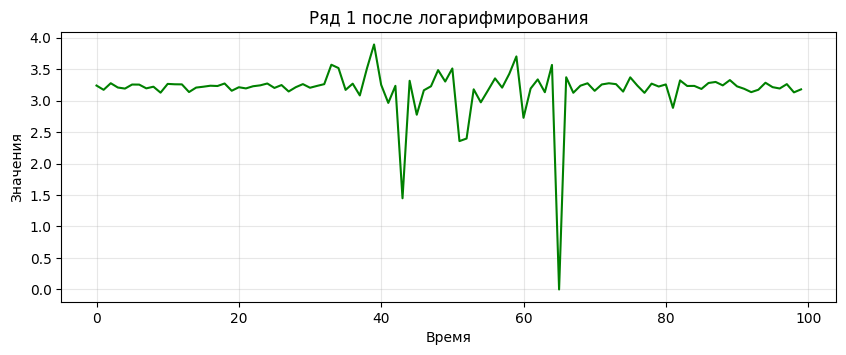

In [6]:

# Логарифмическое преобразование первого ряда
new_ts1 = stationarity_ts1 - stationarity_ts1.min() + 1.0
log_ts1 = np.log(new_ts1)

# График преобразованного ряда
run_sequence_plot(time1, log_ts1,
                  title="Ряд 1 после логарифмирования",
                  xlabel="Время", ylabel="Значения")

plt.show()


In [7]:

chunks_log = np.split(log_ts1, 10)

print("Ряд 1 после логарифмирования")
print("{}\t | {}\t\t | {}".format("Chunk", "Mean", "Variance"))

print("-" * 35)
for i, chunk in enumerate(chunks_log, 1):
    print("{:2}\t | {:.5}\t | {:.5}".format(i, np.mean(chunk), np.var(chunk)))


Ряд 1 после логарифмирования
Chunk	 | Mean		 | Variance
-----------------------------------
 1	 | 3.2124	 | 0.0018257
 2	 | 3.2229	 | 0.0019191
 3	 | 3.2203	 | 0.0012471
 4	 | 3.3697	 | 0.054385
 5	 | 3.0155	 | 0.30753
 6	 | 3.125	 | 0.17748
 7	 | 2.8951	 | 0.97331
 8	 | 3.2303	 | 0.0049166
 9	 | 3.2245	 | 0.014614
10	 | 3.197	 | 0.002215


Поскольку логарифмическое преобразование не обеспечило постоянство дисперсии, дополнительно была применена стандартизация по участкам, выделенным на основе визуального анализа исходного ряда.

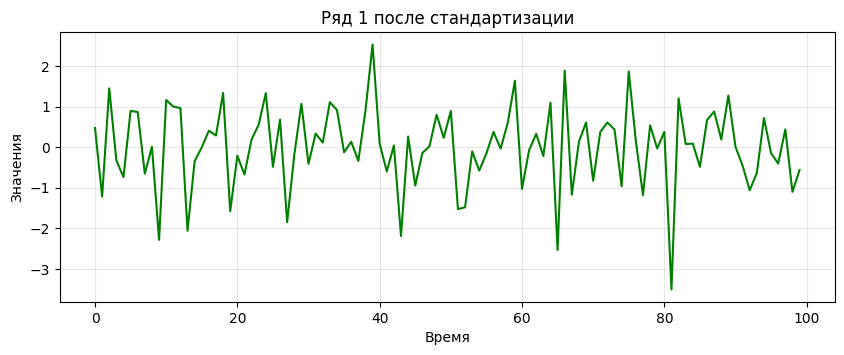

In [8]:

#Разделяем первый ряд на три участка
part1 = stationarity_ts1[:32]
part2 = stationarity_ts1[32:66]
part3 = stationarity_ts1[66:]

# Стандартизация каждого участка
part1 = (part1 - np.mean(part1)) / np.std(part1)
part2 = (part2 - np.mean(part2)) / np.std(part2)
part3 = (part3 - np.mean(part3)) / np.std(part3)

# Объединяем участки обратно
std_ts1 = np.concatenate([part1, part2, part3])
run_sequence_plot(time1, std_ts1,
                  title="Ряд 1 после стандартизации",
                  xlabel="Время", ylabel="Значения")

plt.show()


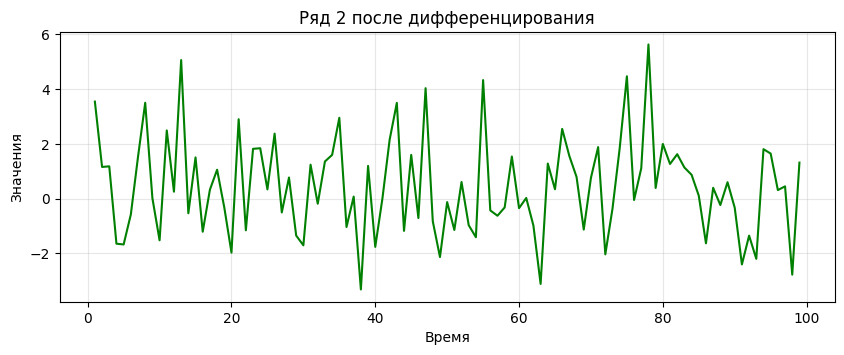

In [9]:
# Дифференцирование первого порядка
diff_ts2 = np.diff(stationarity_ts2)

run_sequence_plot(time2[1:], diff_ts2,
                  title="Ряд 2 после дифференцирования",
                  xlabel="Время", ylabel="Значения")

plt.show()


In [10]:

chunks1 = np.array_split(std_ts1, 10)
chunks2 = np.array_split(diff_ts2, 10)

print("Сводная статистика по фрагментам")
print("Преобразованный ряд 1")
print("{}\t | {}\t\t | {}".format("Chunk", "Mean", "Variance"))
print("-" * 35)
for i, chunk1 in enumerate(chunks1, 1):
    print("{:2}\t | {:.5}\t | {:.5}".format(i, np.mean(chunk1), np.var(chunk1)))

print("Преобразованный ряд 2")
print("{}\t | {}\t\t | {}".format("Chunk", "Mean", "Variance"))
print("-" * 35)
for i, chunk2 in enumerate(chunks2, 1):
    print("{:2}\t | {:.5}\t | {:.5}".format(i, np.mean(chunk2), np.var(chunk2)))



Сводная статистика по фрагментам
Преобразованный ряд 1
Chunk	 | Mean		 | Variance
-----------------------------------
 1	 | -0.15179	 | 1.1412
 2	 | 0.1171	 | 1.2018
 3	 | 0.042006	 | 0.79039
 4	 | 0.51577	 | 0.70545
 5	 | -0.24347	 | 0.62572
 6	 | -0.036653	 | 0.88543
 7	 | -0.096913	 | 1.4083
 8	 | 0.097072	 | 0.74111
 9	 | 0.077056	 | 1.6952
10	 | -0.32017	 | 0.31308
Преобразованный ряд 2
Chunk	 | Mean		 | Variance
-----------------------------------
 1	 | 0.55219	 | 3.5053
 2	 | 0.66756	 | 3.6708
 3	 | 0.53469	 | 2.496
 4	 | 0.21276	 | 3.0888
 5	 | 0.63399	 | 3.887
 6	 | 0.12387	 | 2.6401
 7	 | 0.2081	 | 2.3417
 8	 | 1.4895	 | 4.618
 9	 | 0.38166	 | 0.82084
10	 | -0.35441	 | 3.0046


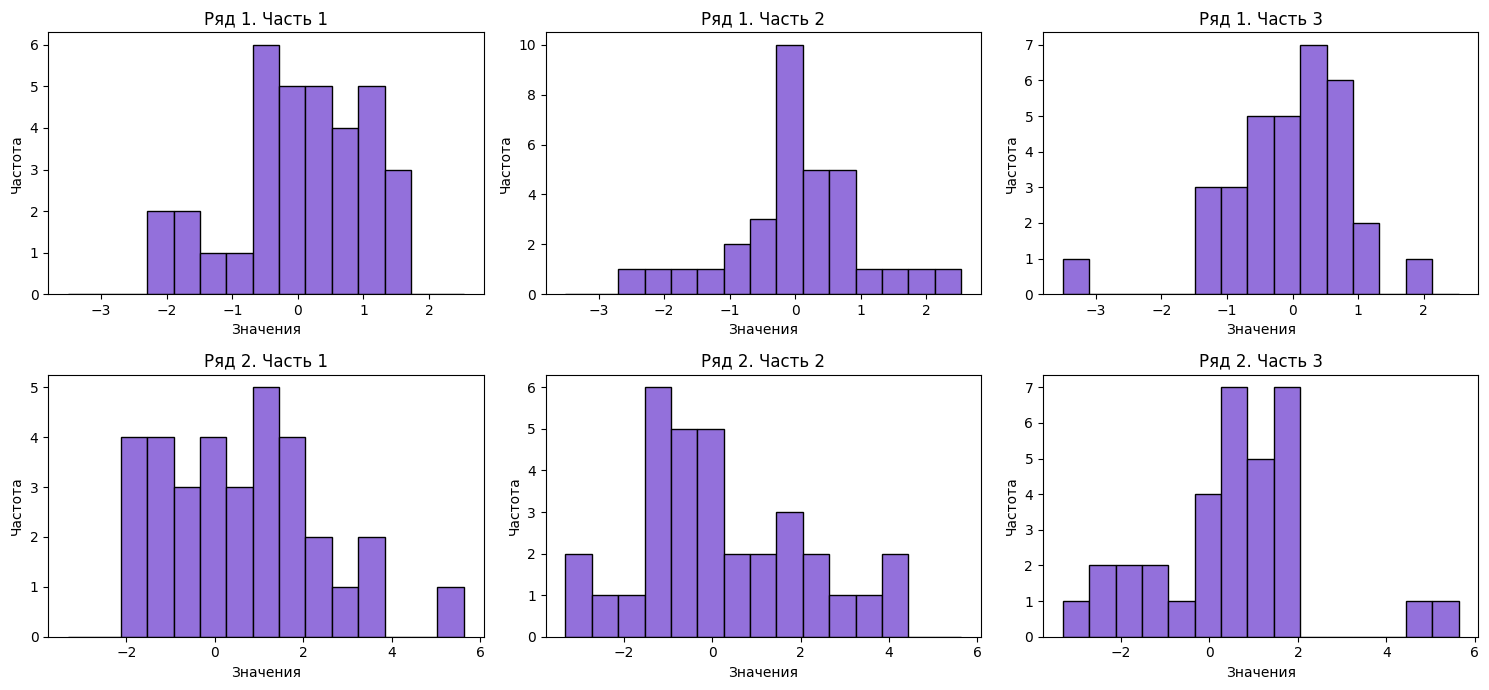

In [11]:
#Гистограммы
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

parts1 = np.array_split(std_ts1, 3)
parts2 = np.array_split(diff_ts2, 3)
bins1 = np.histogram_bin_edges(std_ts1, bins=15)
bins2 = np.histogram_bin_edges(diff_ts2, bins=15)

for i in range(3):
    axes[0, i].hist(parts1[i], bins=bins1, color="mediumpurple", edgecolor="black")
    axes[0, i].set_title(f"Ряд 1. Часть {i + 1}")
    axes[0, i].set_xlabel("Значения")
    axes[0, i].set_ylabel("Частота")
    axes[1, i].hist(parts2[i], bins=bins2, color="mediumpurple", edgecolor="black")
    axes[1, i].set_title(f"Ряд 2. Часть {i + 1}")
    axes[1, i].set_xlabel("Значения")
    axes[1, i].set_ylabel("Частота")

plt.tight_layout()
plt.show()


In [12]:

# ADF для преобразованного первого ряда
adf1, pvalue1, _, _, critical_values1, _ = adfuller(std_ts1)

print("Временной ряд 1 после стандартизации")
print(f"ADF: {adf1:.3f}")
print(f"p-value: {pvalue1:.6f}")
print("Критические значения:", critical_values1)

# ADF для преобразованного второго ряда
adf2, pvalue2, _, _, critical_values2, _ = adfuller(diff_ts2)

print("\nВременной ряд 2 после дифференцирования")
print(f"ADF: {adf2:.3f}")
print(f"p-value: {pvalue2:.6f}")
print("Критические значения:", critical_values2)


Временной ряд 1 после стандартизации
ADF: -12.346
p-value: 0.000000
Критические значения: {'1%': np.float64(-3.498198082189098), '5%': np.float64(-2.891208211860468), '10%': np.float64(-2.5825959973472097)}

Временной ряд 2 после дифференцирования
ADF: -10.280
p-value: 0.000000
Критические значения: {'1%': np.float64(-3.4989097606014496), '5%': np.float64(-2.891516256916761), '10%': np.float64(-2.5827604414827157)}


### Вывод

**1. Преобразование первого временного ряда**

Первоначально было применено логарифмическое преобразование. Несмотря на уменьшение абсолютных значений дисперсии, её неоднородность сохранилась: дисперсия по фрагментам изменяется от 0.00125 до 0.97331. Следовательно, логарифмирование не позволило сделать ряд стационарным.

Дополнительно была применена стандартизация по участкам. После преобразования средние значения фрагментов колеблются около нуля, а дисперсия изменяется от 0.313 до 1.695. На графике наблюдается более равномерный разброс значений, а гистограммы отдельных частей ряда имеют схожее распределение.

**2. Преобразование второго временного ряда**

Для второго ряда было применено дифференцирование первого порядка. В результате восходящий тренд исчез, средние значения фрагментов стали колебаться около постоянного уровня, а дисперсия стала более стабильной. Гистограммы отдельных частей ряда больше не имеют выраженного смещения относительно друг друга.

**3. Проверка стационарности**

Для первого ряда после стандартизации значение ADF составляет −12.346, для второго ряда после дифференцирования - −10.280. В обоих случаях p-value < 0.05, поэтому нулевая гипотеза о наличии единичного корня отвергается.

**Общий вывод:** в результате проведённых преобразований оба временных ряда стали приближённо стационарными. Для первого ряда была стабилизирована дисперсия посредством стандартизации по участкам, а для второго устранён восходящий тренд посредством дифференцирования первого порядка. Полученные результаты подтверждаются визуальным анализом, сводной статистикой, гистограммами и тестом Дики-Фуллера.